# Step 3 · 数据探索与质量验证

本 Notebook 对上海黄浦区交通预测数据执行可复现、只读审查。所有 CSV 均以 `header=None` 读取，避免把第一行真实观测误判为列名。图表由真实数据直接计算，输出为 16:9、300 DPI PNG 与 SVG。

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'pyproject.toml').exists())
SRC = ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from urban_joint_encoder.data_audit import (POI_NAMES, load_all, build_audit, audit_tables, save_json, make_all_figures)
print('Project root:', ROOT)
print('Execution policy: CPU only; source CSV files are read-only')

Project root: /Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder
Execution policy: CPU only; source CSV files are read-only


## 1. 数据读取与结构审查

POI 文件是单行 × 265 列，交通矩阵、邻接矩阵和降水文件也都没有表头。以下读取保留 BOM 后的第一个数值，并对非数值内容直接报错。

In [2]:
bundle = load_all(ROOT)
audit = build_audit(bundle, ROOT)
summary_table, checks_table = audit_tables(audit)
display(summary_table.style.format({'missing_ratio': '{:.4%}', 'zero_ratio': '{:.4%}', 'min': '{:.4f}', 'max': '{:.4f}', 'mean': '{:.4f}', 'std': '{:.4f}'}))

,dataset,shape,dtypes,missing_count,missing_ratio,min,max,mean,std,zero_ratio
0,traffic,"[8640, 265]",['float64'],0,0.0000%,0.0000,39.9740,7.6124,3.5279,0.0010%
1,adjacency,"[265, 265]",['float64'],0,0.0000%,0.0000,1.0000,0.0089,0.0938,99.1114%
2,poi_1,"[1, 265]",['int64'],0,0.0000%,0.0000,34.0000,7.9170,6.1694,3.0189%
3,poi_2,"[1, 265]",['int64'],0,0.0000%,0.0000,168.0000,4.9170,12.1867,26.4151%
4,poi_3,"[1, 265]",['int64'],0,0.0000%,0.0000,55.0000,8.4453,9.5524,7.9245%
5,poi_4,"[1, 265]",['int64'],0,0.0000%,0.0000,25.0000,2.4792,3.5249,35.4717%
6,poi_5,"[1, 265]",['int64'],0,0.0000%,0.0000,107.0000,10.3019,15.0966,16.9811%
7,poi_6,"[1, 265]",['int64'],0,0.0000%,0.0000,12.0000,1.0189,1.8016,58.4906%
8,poi_7,"[1, 265]",['int64'],0,0.0000%,0.0000,90.0000,10.8679,14.1138,16.6038%
9,precipitation_station_1,"[8640, 1]",['float64'],0,0.0000%,0.0000,17.7000,0.1582,0.9490,89.3056%


In [3]:
display(Markdown(f"""
### 核心规模

- 交通矩阵：**{audit['traffic']['time_steps']:,} × {audit['traffic']['spatial_nodes']}**（时间步 × 空间节点）
- POI：**{audit['poi']['category_count']} 类**；至少含一个 POI 的节点 **{audit['poi']['nodes_with_any_poi']}/{audit['traffic']['spatial_nodes']}**（{audit['poi']['coverage_ratio']:.1%}）
- 降水序列长度：**{audit['precipitation']['series_lengths']}**
- 图：**{audit['graph']['nodes']} 节点 / {audit['graph']['edges']} 边**
"""))
display(checks_table)


### 核心规模

- 交通矩阵：**8,640 × 265**（时间步 × 空间节点）
- POI：**7 类**；至少含一个 POI 的节点 **264/265**（99.6%）
- 降水序列长度：**[8640, 8640]**
- 图：**265 节点 / 312 边**


,check,result
0,traffic_columns_equal_adjacency_nodes,True
1,poi_lengths_equal_traffic_nodes,True
2,precipitation_lengths_equal_traffic_steps,True
3,node_identity_order_verified,False
4,time_identity_verified,False


## 2. 原作者数据生成逻辑审查

以下结论来自 `README.md`、`data_manage.ipynb`、`data_manage2.ipynb`、`interpolation.ipynb`、`adj_create.ipynb`、`POI_class_num.ipynb`、`precipitation.ipynb` 与 `utils/data/functions.py`。

### 可以确认

1. `feature_matrix_X.csv` 的行是连续 `batch` 时间片，列是进入黄浦区筛选结果的蜂窝网格；源码先创建 `batch_1` 至 `batch_8640`，并按 `[time, grid]` 导出纯数值矩阵。
2. 8640 个时间片在源码中按 30 天 × 每天 288 片 reshape，因此时间片为 5 分钟；数据背景是 2015 年 4 月。
3. 空间单元来自覆盖上海的边长 125 米规则六边形网格，经与“黄浦区”县界相交筛选后形成当前 265 个节点。严格说是“与黄浦区相交的蜂窝网格”。
4. 交通值来自每个网格/时间片的 `local_avg_speed`。插补前，源码将大于 40 的值标记为缺失，再进行低秩张量补全。
5. 邻接边由 `(h1)<-[:within]-(road1)-[:touch]-(road2)-[:within]->(h2)` 生成；对未连接网格，再沿蜂窝 `adjacency` 关系寻找 1–10 跳最短路径并补一条边。最终矩阵按排序后的网格 ID 构建并去掉标签导出。
6. POI 七类按源码 `sorted()` 后的列顺序导出：交通设施服务、住宿服务、公司企业、医疗保健服务、购物服务、风景名胜、餐饮服务。每个值是对应网格中的 POI 数量。POI 表最初使用交通矩阵的网格列名查询并透视，意图保持节点一致。
7. 两条降水序列分别从徐家汇、浦东源 CSV 的“降水量（mm）”列直接导出。

### 待确认 / 不可从交付文件独立验证

- 纯数值导出删除了蜂窝 FID、时间戳和坐标；因此即使 shape 一致，也不能从当前文件独立证明逐列节点身份或逐行时间身份。
- POI 生成链显示其使用交通列名，邻接生成链也以同一批列名为候选，但邻接矩阵内部采用 `sorted(all_ids)`；需要保留带标签的中间 CSV 才能严格复核两者顺序。
- 降水 notebook 仅抽取原列，没有显示重采样、时间戳校验或时区处理；长度相同只能说明可按位置拼接，不能证明时间语义对齐。
- 源码未明确说明 `local_avg_speed` 的物理单位，故图中不标注 km/h 或 m/s。
- 当前 `prediction_data` 不含经纬度，拓扑图只能使用 spring layout，不能作为真实地图。

> 额外风险：参考 `load_features()` 使用默认 `pd.read_csv(feat_path)`，会把第一条数值记录当作表头并只得到 8639 行；本 Notebook 统一使用 `header=None`，保留 8640 行。

## 3. PPT 级真实数据可视化

统一使用深色高对比度、色盲友好配色。热力图仅为可读性做等距显示采样，统计仍基于全量数据；拓扑布局明确不是地理地图。

findfont: Failed to find font weight bold for PingFang SC, now using 600.


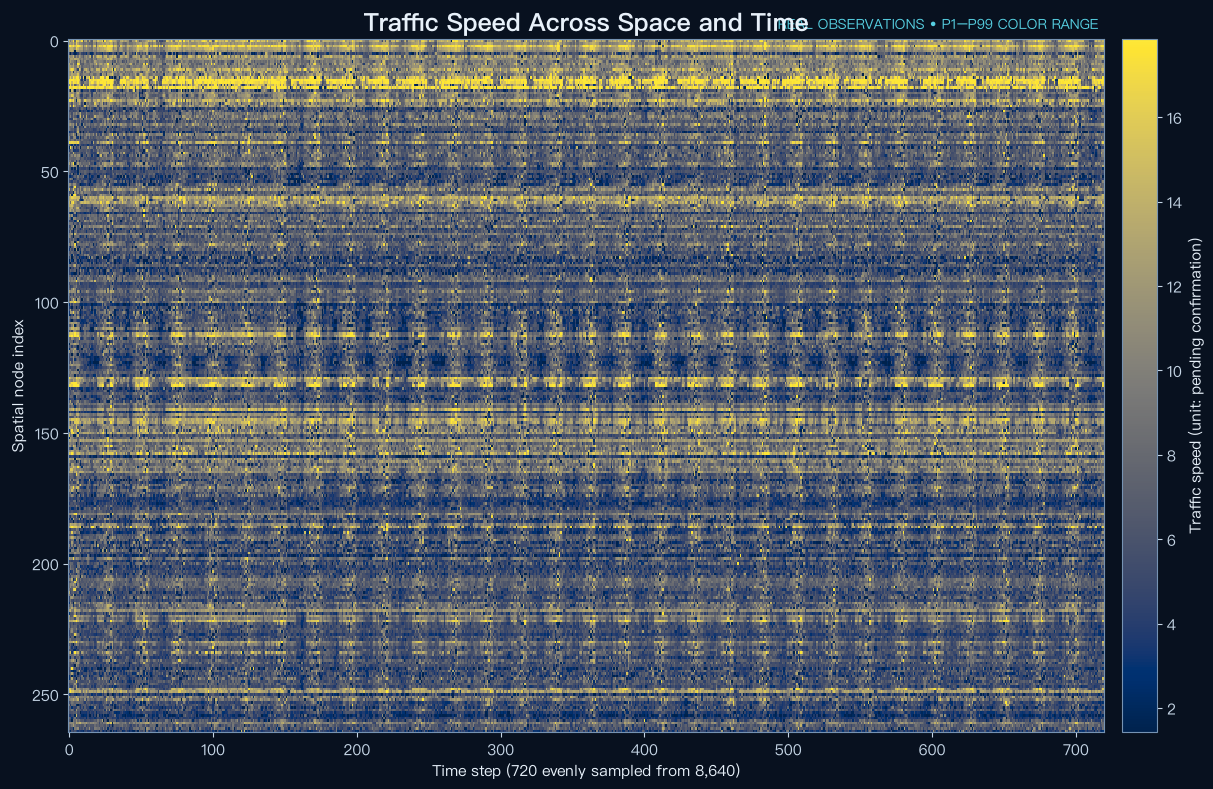

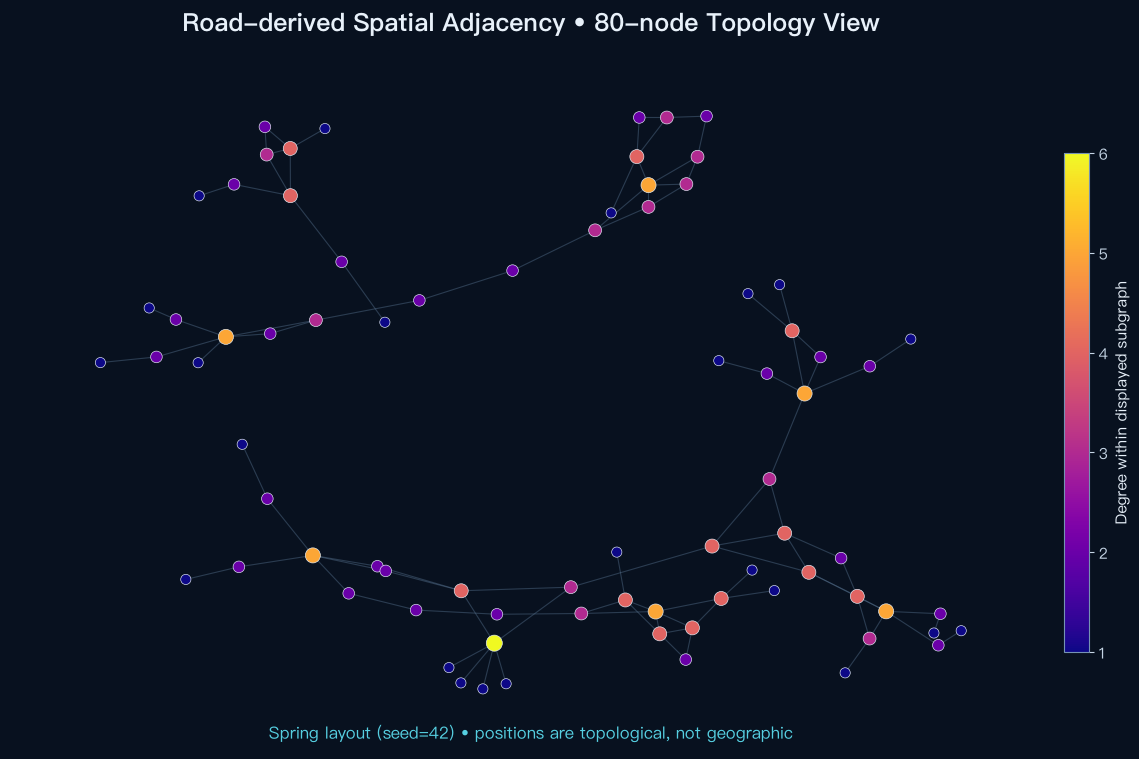

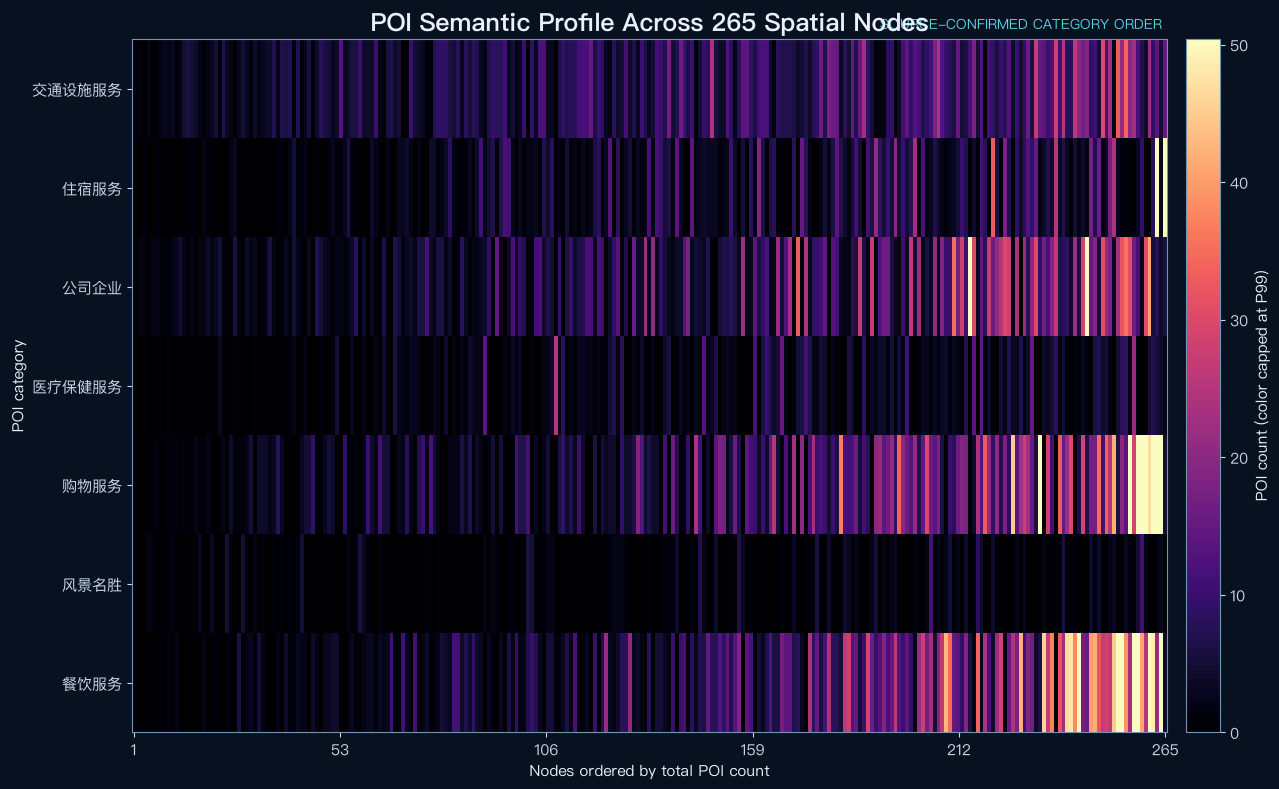

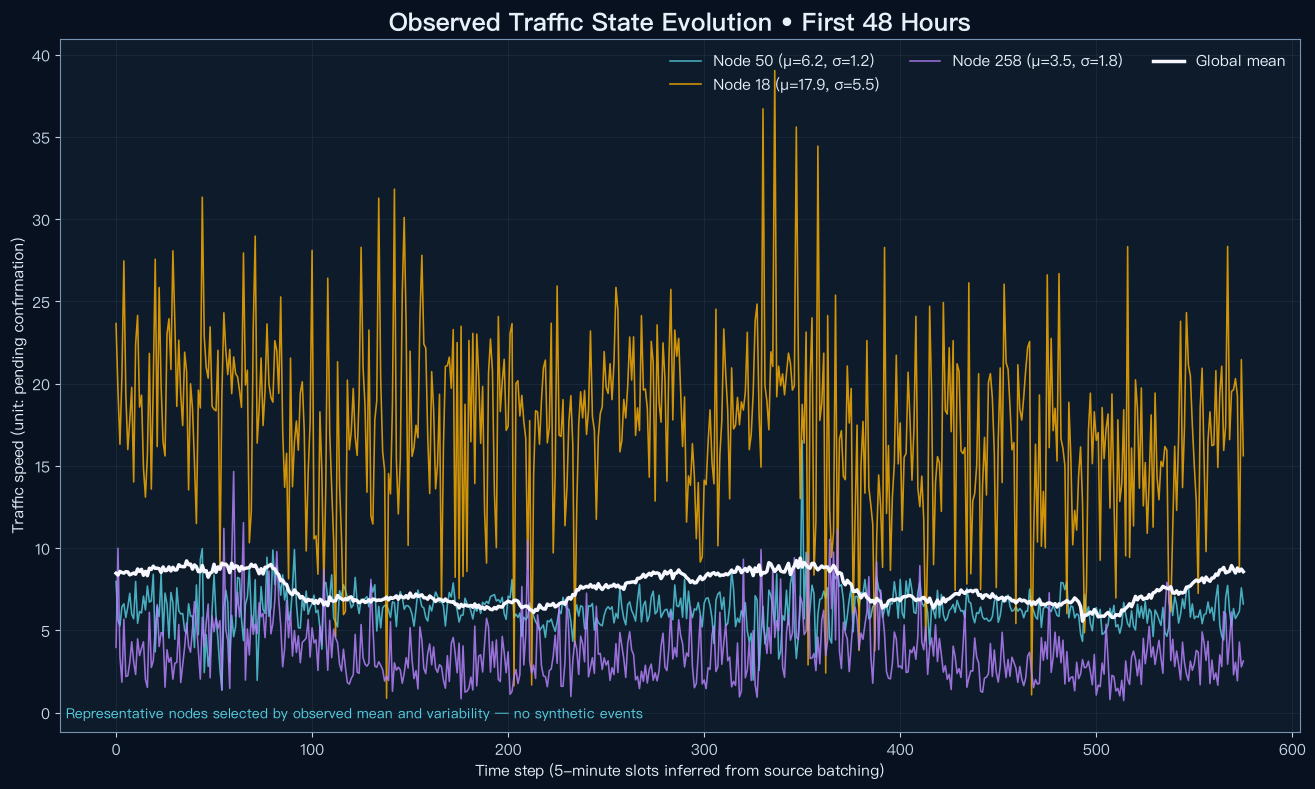

figure_01 : (PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_01_traffic_speed_heatmap.png'), PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_01_traffic_speed_heatmap.svg'))
figure_02 : (PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_02_spatial_adjacency_topology.png'), PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_02_spatial_adjacency_topology.svg'))
figure_03 : (PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_03_poi_semantic_distribution.png'), PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_03_poi_semantic_distribution.svg'))
figure_04 : (PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/figures/figure_04_traffic_state_evolution.png'), PosixPath('/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs

In [4]:
figure_outputs = make_all_figures(bundle, ROOT)
for name, paths in figure_outputs.items():
    print(name, ':', paths)

## 4. 导出机器可读审查报告

报告使用标准 Python `int` / `float` / `bool`，并以 `allow_nan=False` 强制保证合法 JSON。

In [5]:
report_path = ROOT / 'outputs' / 'metrics' / 'data_audit.json'
save_json(audit, report_path)
import json
validated = json.loads(report_path.read_text(encoding='utf-8'))
print('Valid JSON:', report_path)
print('Top-level keys:', list(validated))

Valid JSON: /Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder/outputs/metrics/data_audit.json
Top-level keys: ['generated_by', 'read_policy', 'files', 'traffic', 'poi', 'precipitation', 'graph', 'alignment_checks', 'source_findings', 'known_reference_code_risk']


## 5. Step 4 输入就绪判断

**数值层面已基本具备**：交通序列、265×265 方阵邻接、7 类静态 POI 与两条等长降水序列均可读取，且 shape 兼容；邻接的对称性、二值性、自环和孤立节点已在本页实测。

**可追溯性层面尚未完全具备**：进入时空图编码器前，应优先恢复并固化 `node_id → column_index` 与 `timestamp → row_index` 映射，同时确认速度单位与降水采样/对齐规则。若 Step 4 仅复现作者的按位置输入，可继续；若要求可审计的真实语义对齐，则这些映射是阻塞项。